# Service Clustering 

**Input:** `data/processed/salon_clean.csv`, `outputs/tables/tiers.json`

**Output:** `outputs/tables/service_clusters.csv`

K-Means groups services by four booking-behavior features (adapted from the
Kasavana-Smith menu-engineering approach in Bangkalang et al., 2023):
volume, peak-hour share, median lead time, cancellation rate.
Features use training weeks only so the holdout remains clean for pricing - found in notebook 06.
k chosen from 2-4 by lowest Davies-Bouldin Index (Task 2 C4).

In [1]:
import sys, json; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scenarios import TRAIN_FRAC, SEED

s = pd.read_csv("../data/processed/salon_clean.csv", parse_dates=["appt_dt"])
TIER = {int(k): v for k, v in json.load(open("../outputs/tables/tiers.json")).items()}

n_weeks = int(s["week_index"].max()) + 1
n_train = int(round(n_weeks * TRAIN_FRAC))
tr = s[s["week_index"] < n_train].copy()
print("Training bookings:", len(tr))

# peak share uses hour-valid rows only (the 1:00 record has no tier)
tr["is_peak"] = np.where(tr["hour_valid"], tr["appt_hour"].map(TIER).eq("peak"), np.nan)

feat = tr.groupby("service_group").agg(
    volume=("service_group", "size"),
    peak_share=("is_peak", "mean"),
    median_lead=("lead_days", "median"),      # negatives have been set as missing
    cancel_rate=("cancel_or_noshow", "mean"),
).sort_values("volume", ascending=False)
print(feat.round(3))

# Iteration 2 (CRISP-DM looping back to preparation):
# - Consultation removed: 3 training bookings, free service, no price tier
# - Volume log-transformed: Women's Haircut (37) was an IQR outlier dominating the scale
feat = feat.drop(index="Consultation")
feat["log_volume"] = np.log1p(feat["volume"])
FEATURES = ["log_volume", "peak_share", "median_lead", "cancel_rate"]
print("\nGroups clustered:", len(feat))

Training bookings: 145
                          volume  peak_share  median_lead  cancel_rate
service_group                                                         
Women's Haircut               37       0.444         12.0        0.216
Other                         16       0.312         26.5        0.188
Partial Custom Highlight      16       0.500         25.5        0.062
Signature Blonde Session      12       0.500          6.5        0.250
Full Custom Highlight         11       0.273         10.0        0.000
All Over Color                11       0.545          7.0        0.000
Balayage (Full)               10       0.700         11.0        0.100
Gloss with Haircut            10       0.500         32.0        0.100
Balayage (Partial)             8       0.250         30.5        0.125
Mini Custom Highlight          6       0.167          5.5        0.000
Root Touch-Up with Cut         5       0.600          6.0        0.000
Consultation                   3       0.000          

In [2]:
# IQR outlier check on each feature
f = feat[FEATURES]
q1, q3 = f.quantile(0.25), f.quantile(0.75)
iqr = q3 - q1
outlier = (f < q1 - 1.5 * iqr) | (f > q3 + 1.5 * iqr)
print("IQR outliers (True = flagged):")
print(outlier[outlier.any(axis=1)] if outlier.any().any() else "None")

print("\nSpearman correlation:")
print(f.corr(method="spearman").round(2))

IQR outliers (True = flagged):
                 log_volume  peak_share  median_lead  cancel_rate
service_group                                                    
Women's Haircut        True       False        False        False

Spearman correlation:
             log_volume  peak_share  median_lead  cancel_rate
log_volume         1.00       -0.03         0.32         0.54
peak_share        -0.03        1.00        -0.12        -0.07
median_lead        0.32       -0.12         1.00         0.45
cancel_rate        0.54       -0.07         0.45         1.00


   k    DBI  silhouette  inertia         sizes
0  2  1.289       0.250   28.455        [6, 5]
1  3  0.974       0.284   19.224     [2, 5, 4]
2  4  0.781       0.337   11.405  [2, 2, 4, 3]

Chosen k (lowest DBI): 4


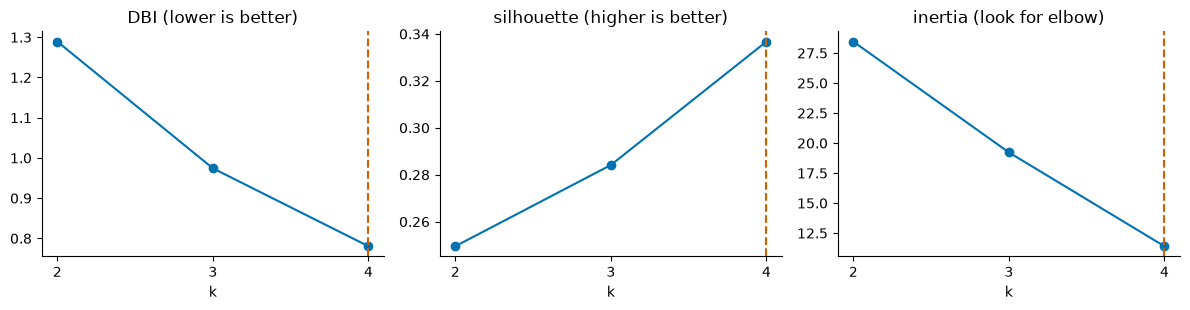

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

X = StandardScaler().fit_transform(feat[FEATURES])

rows = []
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k,
                 "DBI": davies_bouldin_score(X, km.labels_),
                 "silhouette": silhouette_score(X, km.labels_),
                 "inertia": km.inertia_,
                 "sizes": np.bincount(km.labels_).tolist()})
sel = pd.DataFrame(rows)
print(sel.round(3))

best_k = int(sel.loc[sel["DBI"].idxmin(), "k"])
print("\nChosen k (lowest DBI):", best_k)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, goal in zip(axes, ["DBI", "silhouette", "inertia"], ["lower is better", "higher is better", "look for elbow"]):
    ax.plot(sel["k"], sel[col], marker="o", color="#0072B2")
    ax.axvline(best_k, ls="--", color="#D55E00")
    ax.set(title=f"{col} ({goal})", xlabel="k", xticks=[2, 3, 4])
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../outputs/figures/fig05_k_selection.png", dpi=200)
plt.show()

In [4]:
from sklearn.metrics import adjusted_rand_score

final = KMeans(n_clusters=best_k, n_init=20, random_state=SEED).fit(X)
feat["cluster"] = final.labels_

# C4 regarding stability: 20 single-starting runs with different seeds vs the final labels
aris = [adjusted_rand_score(final.labels_,
        KMeans(n_clusters=best_k, n_init=1, random_state=r).fit(X).labels_)
        for r in range(20)]
print(f"Stability (ARI vs final, 20 random starts): mean {np.mean(aris):.3f}, "
      f"min {np.min(aris):.3f}, runs identical to final: {sum(a == 1.0 for a in aris)}/20")

# Cluster names, based on the profiles below
CLUSTER_NAMES = {
    0: "High-volume / high-cancel",
    1: "Off-peak flexible",
    2: "Planned-ahead",
    3: "Peak-driven color",
}
feat["cluster_name"] = feat["cluster"].map(CLUSTER_NAMES)

# Profiles: raw (unscaled) feature means + members
profile = (feat.groupby("cluster")
               .agg(services=("volume", "size"),
                    bookings=("volume", "sum"),
                    peak_share=("peak_share", "mean"),
                    median_lead=("median_lead", "mean"),
                    cancel_rate=("cancel_rate", "mean"))
               .round(3))
profile.index = profile.index.map(CLUSTER_NAMES)
print("\nCluster profiles:")
print(profile)
for c, members in feat.groupby("cluster").groups.items():
    print(f"\n{CLUSTER_NAMES[c]} (cluster {c}): {', '.join(members)}")

Stability (ARI vs final, 20 random starts): mean 0.868, min 0.432, runs identical to final: 13/20

Cluster profiles:
                           services  bookings  peak_share  median_lead  \
cluster                                                                  
High-volume / high-cancel         2        49       0.472        9.250   
Off-peak flexible                 2        17       0.220        7.750   
Planned-ahead                     4        50       0.391       28.625   
Peak-driven color                 3        26       0.615        8.000   

                           cancel_rate  
cluster                                 
High-volume / high-cancel        0.233  
Off-peak flexible                0.000  
Planned-ahead                    0.119  
Peak-driven color                0.033  

High-volume / high-cancel (cluster 0): Women's Haircut, Signature Blonde Session

Off-peak flexible (cluster 1): Full Custom Highlight, Mini Custom Highlight

Planned-ahead (cluster 2): Other

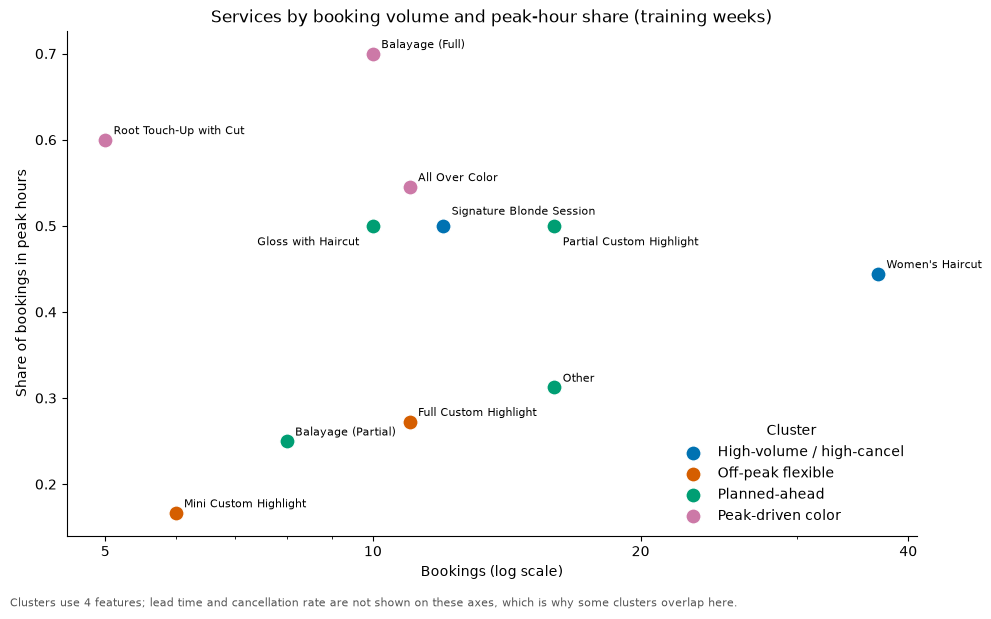

In [5]:
from matplotlib.ticker import NullFormatter

COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]   # color-blind safe
OFFSETS = {"Gloss with Haircut": (-10, -14), "Signature Blonde Session": (6, 8),
           "Partial Custom Highlight": (6, -14)}          # moved overlapping labels

fig, ax = plt.subplots(figsize=(10, 6))
for c in sorted(feat["cluster"].unique()):
    d = feat[feat["cluster"] == c]
    ax.scatter(d["volume"], d["peak_share"], s=120, color=COLORS[c],
               label=CLUSTER_NAMES[c], edgecolor="white", zorder=3)
for name, r in feat.iterrows():
    dx, dy = OFFSETS.get(name, (6, 4))
    ax.annotate(name, (r["volume"], r["peak_share"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8,
                ha="right" if dx < 0 else "left")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 40]); ax.set_xticklabels(["5", "10", "20", "40"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(title="Services by booking volume and peak-hour share (training weeks)",
       xlabel="Bookings (log scale)", ylabel="Share of bookings in peak hours")
ax.legend(frameon=False, loc="lower right", title="Cluster")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Clusters use 4 features; lead time and cancellation rate are not shown "
         "on these axes, which is why some clusters overlap here.", fontsize=8, color="#555555")
fig.tight_layout()
fig.savefig("../outputs/figures/fig06_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
import os
os.makedirs("../outputs/tables", exist_ok=True)
out = feat.copy()
out.loc["Consultation", ["volume", "cluster", "cluster_name"]] = [3, -1, "Not clustered (free)"]
out[["volume", "cluster"]] = out[["volume", "cluster"]].astype(int)
out.to_csv("../outputs/tables/service_clusters.csv")
print(out[["volume", "cluster", "cluster_name"]])

                          volume  cluster               cluster_name
service_group                                                       
Women's Haircut               37        0  High-volume / high-cancel
Other                         16        2              Planned-ahead
Partial Custom Highlight      16        2              Planned-ahead
Signature Blonde Session      12        0  High-volume / high-cancel
Full Custom Highlight         11        1          Off-peak flexible
All Over Color                11        3          Peak-driven color
Balayage (Full)               10        3          Peak-driven color
Gloss with Haircut            10        2              Planned-ahead
Balayage (Partial)             8        2              Planned-ahead
Mini Custom Highlight          6        1          Off-peak flexible
Root Touch-Up with Cut         5        3          Peak-driven color
Consultation                   3       -1       Not clustered (free)


## Insights and Findings
- Final features: log volume, peak share, median lead, cancel rate (11 service groups; Consultation excluded as it skewed findings)

- k = 4 (lowest DBI): DBI 0.781 meets target; silhouette 0.337 misses 0.40 target

- Stability: mean ARI 0.868 over 20 random starts; 13/20 identical to final

- Peak-driven color (All Over Color, Balayage Full, Root Touch-Up w/ Cut): 62% peak, 3% cancel

- Off-peak flexible (Full and Mini Custom Highlight): 22% peak, 0% cancel

- Planned-ahead (Other, Partial Highlight, Gloss w/ Haircut, Balayage Partial): 29-day lead

- High-volume / high-cancel (Women's Haircut, Signature Blonde): 23% cancel/no-show